In [10]:
import scipy.stats  
from scipy.stats import linregress as linregress
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [11]:
gemiddelde_data = np.loadtxt('gemiddelden.dat', skiprows=1)
u = gemiddelde_data[:, 1]   
z = gemiddelde_data[:, 0]
print(z,u)

[ 2.7  7.3 10.6 16.8 23.3 29.7 36.  42.4 48.8 55.3 61.5 74.4 87.  94.4] [0.42801102 0.64251997 0.71085226 0.83158025 0.91985018 0.9716647
 1.0202044  1.02521767 1.07753436 1.11098517 1.13336134 1.13446589
 1.14874626 1.15487134]


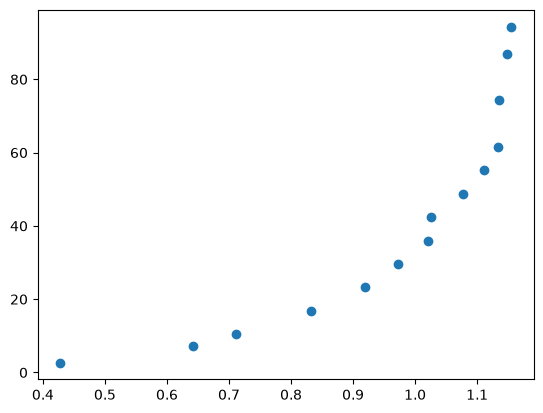

In [8]:
plt.plot(u, z, 'o', label='Data')



Slope = 0.2142015588320112
Intercept = 0.22584544879393198
Friction velocity = 0.08782263912112459 m/s
Roughness length = 0.34841551546443794 m
R² = 0.9888700217180532


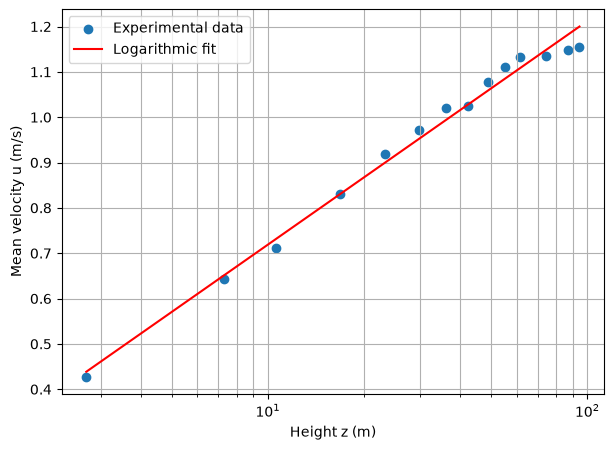

In [12]:
kappa = 0.41

# Transform height to natural logarithmic scale
ln_z = np.log(z)

# Linear regression: u = a*ln(z) + b
slope, intercept, r_value, p_value, std_err = linregress(ln_z, u)

# Calculate parameters
u_star = slope * kappa
z0 = np.exp(-intercept / slope)

print("Slope =", slope)
print("Intercept =", intercept)
print("Friction velocity =", u_star, "m/s")
print("Roughness length =", z0, "m")
print("R² =", r_value**2)

# Plot
z_fit = np.linspace(min(z), max(z), 200)
u_fit = slope * np.log(z_fit) + intercept

plt.figure(figsize=(7,5))
plt.scatter(z, u, label="Experimental data")
plt.plot(z_fit, u_fit, 'r-', label="Logarithmic fit")

plt.xscale('log')  # Logarithmic x-axis
plt.xlabel("Height z (m)")
plt.ylabel("Mean velocity u (m/s)")
plt.legend()
plt.grid(True, which="both")
plt.show()

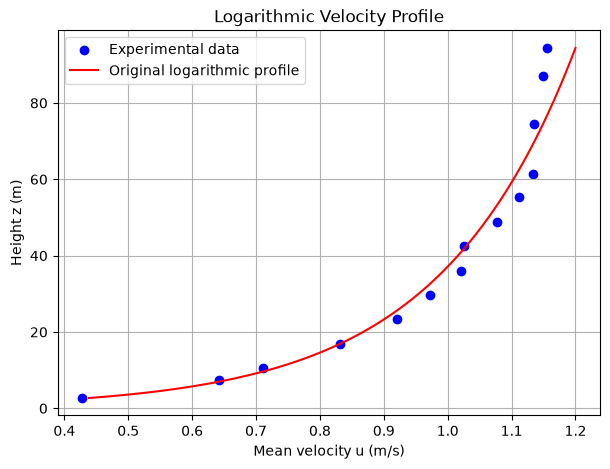

Friction velocity (u*): 0.08782263912112459 m/s
Roughness length (z0): 0.34841551546443794 m


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters obtained from linear regression
kappa = 0.41

u_star = slope * kappa
z0 = np.exp(-intercept / slope)

# Original logarithmic profile
z_fit = np.linspace(min(z), max(z), 200)

u_original = (u_star / kappa) * np.log(z_fit / z0)

# Plot in normal (linear) coordinates
plt.figure(figsize=(7,5))

plt.scatter(u, z, color='blue', label='Experimental data')
plt.plot( u_original, z_fit, 'r-', label='Original logarithmic profile')

plt.ylabel('Height z (m)')
plt.xlabel('Mean velocity u (m/s)')
plt.title('Logarithmic Velocity Profile')

plt.xscale('linear')
plt.yscale('linear')

plt.grid(True)
plt.legend()
plt.show()
print("Friction velocity (u*):", u_star, "m/s")
print("Roughness length (z0):", z0, "m")
